In [81]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Constants
DATASET_PATH = '../demo'
IMAGE_SIZE = (32, 32)
BATCH_SIZE = 32
VALIDATION_SPLIT = 0.2
RESCALE_VALUE = 1./255
CLASS_MODE = 'binary'

# Training and Validation Data Generator
train_datagen = ImageDataGenerator(
    rescale=RESCALE_VALUE,
    validation_split=VALIDATION_SPLIT
)

train_generator = train_datagen.flow_from_directory(
    f'{DATASET_PATH}/train',
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode=CLASS_MODE,
    subset='training',
    shuffle=True
)

validation_generator = train_datagen.flow_from_directory(
    f'{DATASET_PATH}/train',
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode=CLASS_MODE,
    subset='validation',
    shuffle=False
)

# Testing Data Generator
test_datagen = ImageDataGenerator(
    rescale=RESCALE_VALUE
)

test_generator = test_datagen.flow_from_directory(
    f'{DATASET_PATH}/test',
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode=CLASS_MODE,
    shuffle=False
)

Found 800 images belonging to 2 classes.
Found 200 images belonging to 2 classes.


Found 500 images belonging to 2 classes.


In [82]:
import os

classes = ['deer', 'horse']

print("===== DATASET EXPLORATION =====")

# Training dataset
print("\n--- TRAIN DATASET ---")

train_total = 0

for class_name in classes:
    class_path = os.path.join(dataset_path, 'train', class_name)

    num_images = len([
        f for f in os.listdir(class_path)
        if f.lower().endswith(('.jpg', '.jpeg', '.png'))
    ])

    train_total += num_images

    print(f"{class_name}: {num_images} images")

print(f"Total Training Images: {train_total}")


# Testing dataset
print("\n--- TEST DATASET ---")

test_total = 0

for class_name in classes:
    class_path = os.path.join(dataset_path, 'test', class_name)

    num_images = len([
        f for f in os.listdir(class_path)
        if f.lower().endswith(('.jpg', '.jpeg', '.png'))
    ])

    test_total += num_images

    print(f"{class_name}: {num_images} images")

print(f"Total Testing Images: {test_total}")


# Overall dataset
print("\n--- OVERALL DATASET ---")
print(f"Total Images: {train_total + test_total}")

===== DATASET EXPLORATION =====

--- TRAIN DATASET ---
deer: 500 images
horse: 500 images
Total Training Images: 1000

--- TEST DATASET ---
deer: 250 images
horse: 250 images
Total Testing Images: 500

--- OVERALL DATASET ---
Total Images: 1500


In [83]:
print("Class Mapping:", train_generator.class_indices)

Class Mapping: {'deer': 0, 'horse': 1}


In [84]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from collections import Counter

classes = ['deer', 'horse']
splits = ['train', 'test']

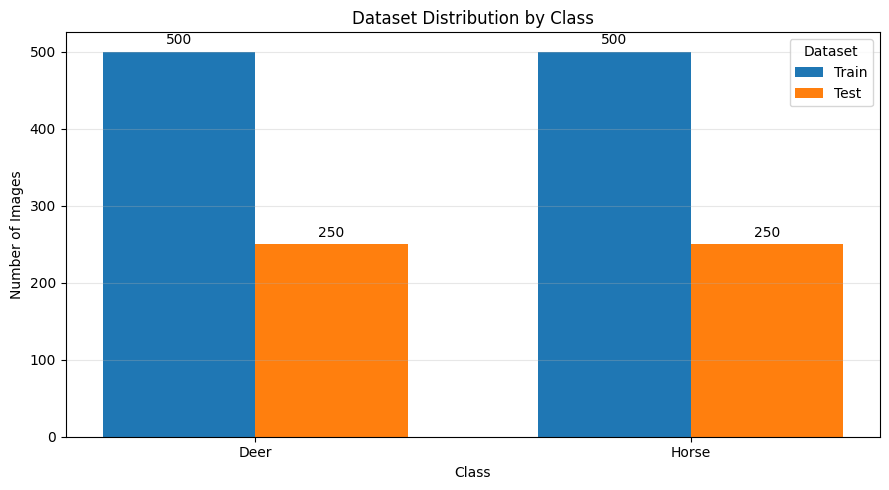

In [85]:
import os
import numpy as np
import matplotlib.pyplot as plt

# Store image counts
distribution = {}

for split in splits:
    distribution[split] = []

    for class_name in classes:
        folder_path = os.path.join(
            dataset_path, split, class_name
        )

        images = [
            f for f in os.listdir(folder_path)
            if f.lower().endswith(
                ('.jpg', '.jpeg', '.png', '.bmp')
            )
        ]

        distribution[split].append(len(images))

# Display chart
x = np.arange(len(classes))
width = 0.35

plt.figure(figsize=(9, 5))

for i, split in enumerate(splits):
    offset = (i - (len(splits) - 1) / 2) * width

    bars = plt.bar(
        x + offset,
        distribution[split],
        width,
        label=split.capitalize()
    )

    plt.bar_label(bars, padding=3)

plt.title('Dataset Distribution by Class')
plt.xlabel('Class')
plt.ylabel('Number of Images')
plt.xticks(x, [name.capitalize() for name in classes])
plt.legend(title='Dataset')
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

In [86]:
print("===== IMAGE DIMENSIONS =====")

for split in splits:
    print(f"\n{split.upper()} DATASET")

    dimensions = []

    for class_name in classes:
        folder_path = os.path.join(
            dataset_path, split, class_name
        )

        for filename in os.listdir(folder_path):
            if filename.lower().endswith(
                ('.jpg', '.jpeg', '.png', '.bmp')
            ):
                img_path = os.path.join(
                    folder_path, filename
                )

                with Image.open(img_path) as img:
                    dimensions.append(img.size)

    dimension_counts = Counter(dimensions)

    for dimension, count in dimension_counts.items():
        print(f"Size {dimension}: {count} images")

    print("Unique dimensions:", len(dimension_counts))

===== IMAGE DIMENSIONS =====

TRAIN DATASET
Size (32, 32): 1000 images
Unique dimensions: 1

TEST DATASET
Size (32, 32): 500 images
Unique dimensions: 1


In [87]:
print("===== IMAGE COLOR MODE =====")

for split in splits:
    print(f"\n{split.upper()} DATASET")

    modes = Counter()

    for class_name in classes:
        folder_path = os.path.join(
            dataset_path, split, class_name
        )

        for filename in os.listdir(folder_path):
            if filename.lower().endswith(
                ('.jpg', '.jpeg', '.png', '.bmp')
            ):
                img_path = os.path.join(
                    folder_path, filename
                )

                with Image.open(img_path) as img:
                    modes[img.mode] += 1

    for mode, count in modes.items():
        print(f"{mode}: {count} images")

===== IMAGE COLOR MODE =====

TRAIN DATASET
RGB: 1000 images

TEST DATASET
RGB: 500 images


In [88]:
print("===== PIXEL VALUE ANALYSIS =====")

for split in splits:

    pixel_values = []

    for class_name in classes:
        folder_path = os.path.join(
            dataset_path, split, class_name
        )

        for filename in os.listdir(folder_path):
            if filename.lower().endswith(
                ('.jpg', '.jpeg', '.png', '.bmp')
            ):
                img_path = os.path.join(
                    folder_path, filename
                )

                with Image.open(img_path) as img:
                    img_array = np.array(img)

                    pixel_values.append(img_array.flatten())

    pixel_values = np.concatenate(pixel_values)

    print(f"\n{split.upper()} DATASET")
    print("Minimum pixel:", pixel_values.min())
    print("Maximum pixel:", pixel_values.max())
    print("Mean pixel:", pixel_values.mean())
    print("Standard deviation:", pixel_values.std())

===== PIXEL VALUE ANALYSIS =====

TRAIN DATASET
Minimum pixel: 0
Maximum pixel: 255
Mean pixel: 115.36216178385416
Standard deviation: 58.82282155134677

TEST DATASET
Minimum pixel: 0
Maximum pixel: 255
Mean pixel: 113.12512109375
Standard deviation: 57.77602561944327


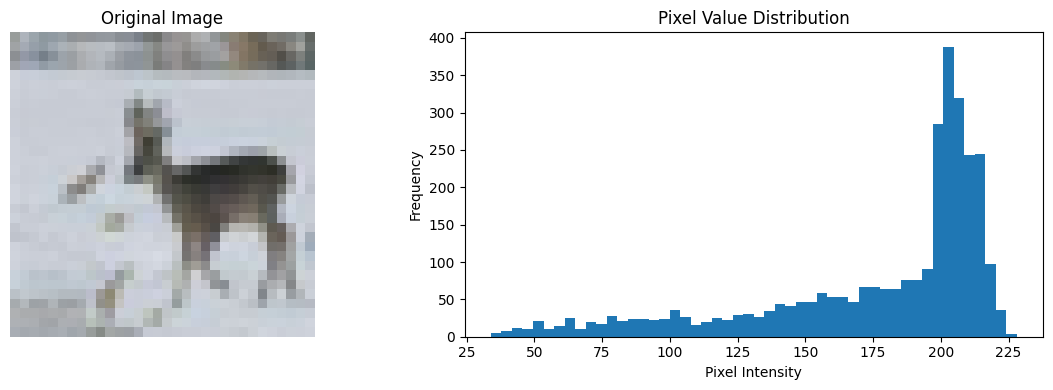

In [89]:
sample_path = os.path.join(
    dataset_path, 'train', 'deer'
)

sample_image = os.listdir(sample_path)[0]

img = Image.open(
    os.path.join(sample_path, sample_image)
)

img_array = np.array(img)

# Plot image and histogram
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].imshow(img)
axes[0].set_title("Original Image")
axes[0].axis('off')

axes[1].hist(
    img_array.flatten(),
    bins=50
)

axes[1].set_title("Pixel Value Distribution")
axes[1].set_xlabel("Pixel Intensity")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

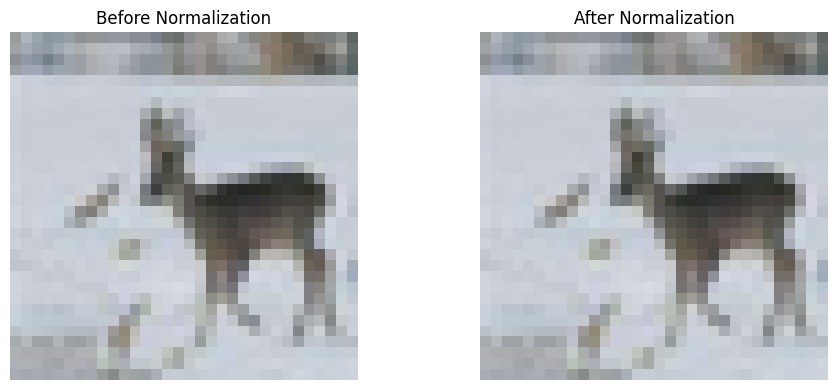

Before: 34.0 - 228.0
After: 0.13333334 - 0.89411765


In [90]:
# Original image
img = np.array(img).astype('float32')

# Normalization
normalized_img = img / 255.0

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].imshow(img.astype('uint8'))
axes[0].set_title("Before Normalization")
axes[0].axis('off')

axes[1].imshow(normalized_img)
axes[1].set_title("After Normalization")
axes[1].axis('off')

plt.tight_layout()
plt.show()

print("Before:", img.min(), "-", img.max())
print("After:", normalized_img.min(), "-", normalized_img.max())

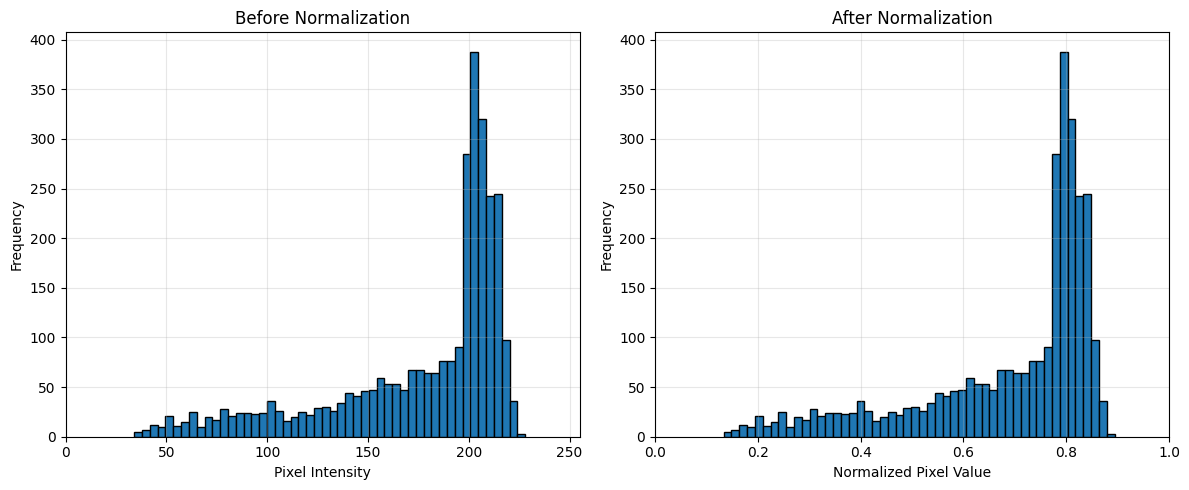

In [91]:
plt.figure(figsize=(12, 5))

# Before Normalization
plt.subplot(1, 2, 1)
plt.hist(img.flatten(), bins=50, edgecolor='black')
plt.title('Before Normalization')
plt.xlabel('Pixel Intensity')
plt.ylabel('Frequency')
plt.xlim(0, 255)
plt.grid(alpha=0.3)

# After Normalization
plt.subplot(1, 2, 2)
plt.hist(normalized_img.flatten(), bins=50, edgecolor='black')
plt.title('After Normalization')
plt.xlabel('Normalized Pixel Value')
plt.ylabel('Frequency')
plt.xlim(0, 1)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [92]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense
)

In [93]:
model = Sequential([
    # Input layer and Convolution Layer 1
    Conv2D(
        32,
        (3, 3),
        activation='relu',
        input_shape=(32, 32, 3)
    ),

    # Pooling Layer 1
    MaxPooling2D(pool_size=(2, 2)),

    # Convolution Layer 2
    Conv2D(
        64,
        (3, 3),
        activation='relu'
    ),

    # Pooling Layer 2
    MaxPooling2D(pool_size=(2, 2)),

    # Flatten Layer
    Flatten(),

    # Fully Connected Layer
    Dense(64, activation='relu'),

    # Output Layer
    Dense(1, activation='sigmoid')
])

c:\Users\Titan\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [94]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [95]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

In [96]:
history = model.fit(
    train_generator,
    epochs=20,
    validation_data=validation_generator,
    callbacks=[early_stopping]
)

Epoch 1/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.5500 - loss: 0.6830 - val_accuracy: 0.6900 - val_loss: 0.6424
Epoch 2/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.6712 - loss: 0.6185 - val_accuracy: 0.6750 - val_loss: 0.5826
Epoch 3/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.7025 - loss: 0.5718 - val_accuracy: 0.6850 - val_loss: 0.5944
Epoch 4/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.7350 - loss: 0.5300 - val_accuracy: 0.7950 - val_loss: 0.4950
Epoch 5/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.7625 - loss: 0.4856 - val_accuracy: 0.8100 - val_loss: 0.4388
Epoch 6/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.8025 - loss: 0.4385 - val_accuracy: 0.7800 - val_loss: 0.4568
Epoch 7/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.8000 - loss: 0.4433 - val_accuracy: 0.8000 - val_loss: 0.4252
Epoch 8/20
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.8450 - loss: 0.3816 - val_accuracy: 0.8150 - v

In [97]:
test_loss, test_accuracy = model.evaluate(test_generator)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.7940 - loss: 0.4563
Test Loss: 0.45631495118141174
Test Accuracy: 0.7940000295639038


In [98]:
import numpy as np
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

test_generator.reset()

y_true = test_generator.classes
predictions = model.predict(test_generator)
y_pred = (predictions > 0.5).astype(int).flatten()

print("Accuracy :", accuracy_score(y_true, y_pred))
print("Precision:", precision_score(y_true, y_pred, zero_division=0))
print("Recall   :", recall_score(y_true, y_pred, zero_division=0))
print("F1-Score :", f1_score(y_true, y_pred, zero_division=0))

16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step
Accuracy : 0.794
Precision: 0.7975708502024291
Recall   : 0.788
F1-Score : 0.7927565392354124


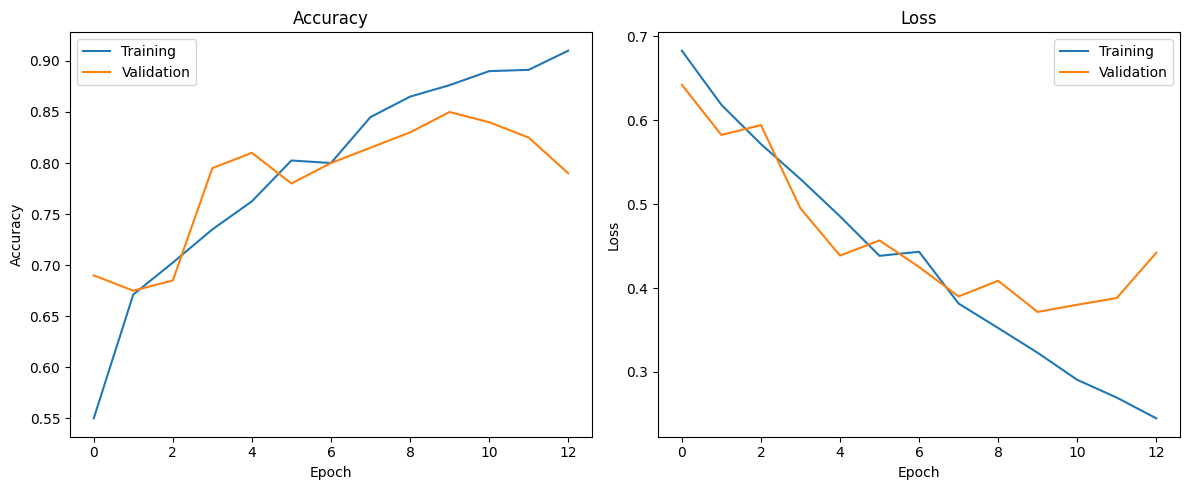

In [99]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training')
plt.plot(history.history['val_accuracy'], label='Validation')
plt.title('Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training')
plt.plot(history.history['val_loss'], label='Validation')
plt.title('Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()